# 环境测试 & 第一次量化代码

quant 环境（Python 3.11）。把下面每个代码框（cell）从上到下依次运行：
选中代码框，按 **Shift + Enter** 执行并跳到下一个。
全部无报错、能看到输出，就说明环境完全正常。

## 1. 确认各个库都能导入、看版本号

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False
import scipy, statsmodels, sklearn
import akshare as ak

print('numpy :', np.__version__)
print('pandas:', pd.__version__)
print('scipy :', scipy.__version__)
print('akshare:', ak.__version__)
print('环境正常，可以开始学习！')

numpy : 2.4.6
pandas: 3.0.6
scipy : 1.17.1
akshare: 1.19.1
环境正常，可以开始学习！


## 2. numpy 小例子：算一组收益率的均值和标准差

假设某股票连续 5 天的日收益率（小数表示，0.02 = 2%）。

In [7]:
ret = np.array([0.02, -0.01, 0.015, 0.005, -0.02])
print('平均日收益率:', round(ret.mean(), 4))
print('收益率标准差(波动率):', round(ret.std(ddof=1), 4))

平均日收益率: 0.002
收益率标准差(波动率): 0.0168


## 3. pandas 小例子：用表格表示股价，并算每日收益率

In [8]:
df = pd.DataFrame({
    '收盘价': [10.0, 10.2, 10.1, 10.3, 10.25]
})
df['日收益率'] = df['收盘价'].pct_change()   # 相邻两天涨跌幅
df

,收盘价,日收益率
0,10.00,NaN
1,10.20,0.020000
2,10.10,-0.009804
3,10.30,0.019802
4,10.25,-0.004854


## 4. 画一张简单的收盘价折线图

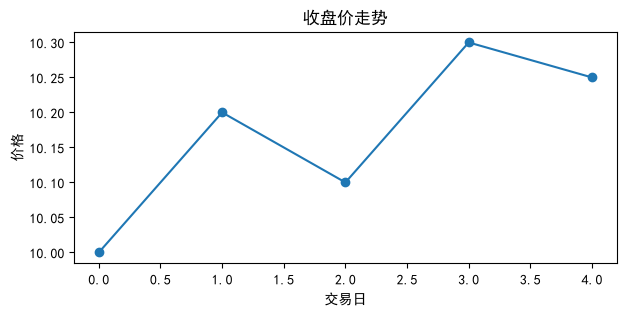

In [9]:
df['收盘价'].plot(marker='o', figsize=(7, 3), title='收盘价走势')
plt.xlabel('交易日')
plt.ylabel('价格')
plt.show()

In [10]:
## 5.（可选，需联网）用 akshare 拉一只真实股票的行情

tushare/baostock 需要 token 或注册；akshare 这个接口可直接用。
若网络或接口变动报错，跳过即可，不影响后续学习。

SyntaxError: invalid character '；' (U+FF1B) (2870695985.py, line 3)

In [11]:
# 拉取平安银行(000001)最近一段日线行情
data = ak.stock_zh_a_hist(symbol='000001', period='daily',
                          start_date='20260101', end_date='20261012')
print(data.shape)
data.tail()

ProxyError: HTTPSConnectionPool(host='push2his.eastmoney.com', port=443): Max retries exceeded with url: /api/qt/stock/kline/get?fields1=f1%2Cf2%2Cf3%2Cf4%2Cf5%2Cf6&fields2=f51%2Cf52%2Cf53%2Cf54%2Cf55%2Cf56%2Cf57%2Cf58%2Cf59%2Cf60%2Cf61%2Cf116&ut=7eea3edcaed734bea9cbfc24409ed989&klt=101&fqt=0&secid=0.000001&beg=20260101&end=20261012 (Caused by ProxyError('Unable to connect to proxy', RemoteDisconnected('Remote end closed connection without response')))